# Yield Curve Construction, Swaps and Bond Risk

**Goal.** Every fixed-income price starts with a discount curve. This project builds one
from market quotes the way a rates desk does, then uses it to value and risk-manage an
interest rate swap and a bond.

1. **Bootstrap** a discount curve from deposits (1M to 6M) and par swap rates (1Y to 30Y)
2. Read **zero and forward curves** and fit the **Nelson-Siegel-Svensson** model
3. Price a 10-year **swap** and compute its **DV01** and **key-rate DV01s**
4. **Bond analytics**: yield, duration, convexity and the quality of the approximations

Market quotes are illustrative of a euro curve in 2026.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("curve.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/08-yield-curve-swaps")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from curve import (MarketQuotes, bootstrap, par_swap_rate, swap_npv, dv01, key_rate_dv01s, fit_nss, nss_zero,
                   bond_price_from_curve, bond_price_from_yield, yield_to_maturity, bond_risk)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
quotes = MarketQuotes()
pd.concat([pd.Series({f"{round(t * 12)}M deposit": r for t, r in quotes.deposits.items()}),
           pd.Series({f"{t}Y swap": r for t, r in quotes.swaps.items()})]).mul(100).round(3).to_frame("Quote (%)").T

,1M deposit,3M deposit,6M deposit,1Y swap,2Y swap,3Y swap,4Y swap,5Y swap,7Y swap,10Y swap,15Y swap,20Y swap,30Y swap
Quote (%),2.0,2.05,2.1,2.15,2.22,2.3,2.37,2.44,2.55,2.66,2.76,2.79,2.75


## 1. Bootstrapping

- **Deposit** of maturity $t$ at simple rate $R$: $P(t) = 1/(1 + R\,t)$.
- **Par swap** of maturity $T$ at rate $S$: the fixed leg equals the floating leg,
  $S \sum_{i=1}^{T} P(t_i) = 1 - P(T)$ (single-curve framework).

Pillars are solved one after another. Between pillars, $\ln P$ is interpolated linearly,
which means piecewise-flat forward rates. The 6Y, 8Y and 9Y discount factors needed by
the 7Y and 10Y swaps come from this interpolation, so each pillar is found with a
root-finder (Brent).

In [2]:
curve = bootstrap(quotes)
check = pd.DataFrame({"Quote": quotes.swaps.values(), "Repriced": [par_swap_rate(curve, T) for T in quotes.swaps]},
                     index=[f"{T}Y" for T in quotes.swaps])
check["Error (bp)"] = (check["Repriced"] - check["Quote"]) * 1e4
print("Every swap reprices exactly:", f"max error {check['Error (bp)'].abs().max():.1e} bp")
pd.DataFrame({"Discount factor": curve.df(curve.times), "Zero rate (%)": curve.zero(curve.times) * 100},
             index=np.round(curve.times, 3)).iloc[1:].round(5).T

Every swap reprices exactly: max error 2.8e-12 bp


,0.083,0.250,0.500,1.000,2.000,3.000,4.000,5.000,7.000,10.000,15.000,20.000,30.000
Discount factor,0.99834,0.99490,0.98961,0.97895,0.95702,0.93399,0.91041,0.88614,0.83767,0.76759,0.66185,0.57339,0.44241
Zero rate (%),1.99834,2.04476,2.08905,2.12721,2.19648,2.27629,2.34664,2.41767,2.53038,2.64500,2.75141,2.78091,2.71840


## 2. Zero curve, forward curve and Nelson-Siegel-Svensson

The **forward curve** is the most sensitive view: any kink in the interpolation shows up
there. NSS describes the curve with 6 parameters (level, slope, two humps). Central banks
publish their curves in this form, and it is useful for scenario analysis.

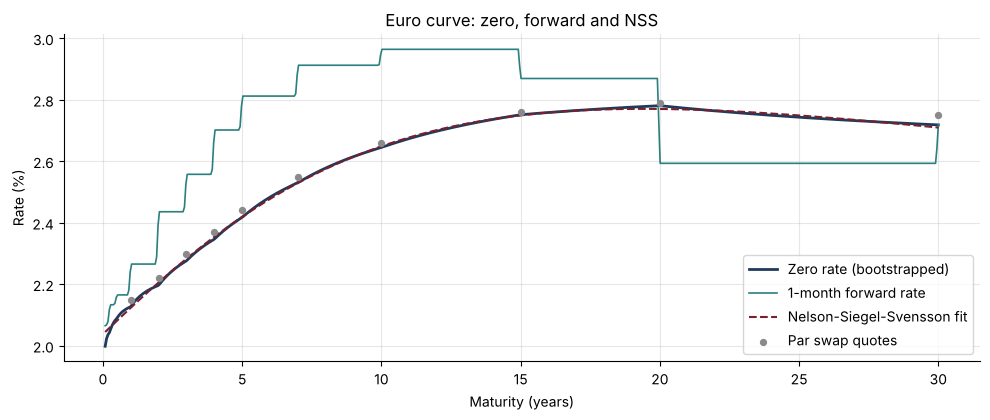

,beta0 (level),beta1 (slope),beta2 (hump 1),beta3 (hump 2),tau1,tau2
NSS,0.0216,-0.0013,-0.0113,0.0311,5.0,8.2781


In [3]:
t = np.linspace(0.08, 30, 600)
nss = fit_nss(t, curve.zero(t))
fwd = curve.forward(t, t + 1 / 12)
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(t, curve.zero(t) * 100, color=NAVY, lw=2, label="Zero rate (bootstrapped)")
ax.plot(t, fwd * 100, color=TEAL, lw=1.2, label="1-month forward rate")
ax.plot(t, nss_zero(t, *nss) * 100, color=BORDEAUX, ls="--", label="Nelson-Siegel-Svensson fit")
ax.scatter(list(quotes.swaps), np.array(list(quotes.swaps.values())) * 100, color=GREY, zorder=3, s=18, label="Par swap quotes")
ax.set(xlabel="Maturity (years)", ylabel="Rate (%)", title="Euro curve: zero, forward and NSS")
ax.legend(); plt.tight_layout(); plt.savefig("images/curves.png", dpi=150); plt.show()
pd.Series(nss, index=["beta0 (level)", "beta1 (slope)", "beta2 (hump 1)", "beta3 (hump 2)", "tau1", "tau2"]).round(4).to_frame("NSS").T

**Reading the chart.** The curve is upward sloping up to 20 years, then slightly inverts.
The forward curve shows steps, the price of the simple log-linear interpolation: smoother
schemes (monotone convex, splines on forwards) are used in production.

## 3. A 10-year interest rate swap

A client **pays fixed at 3.00%** on €10m for 10 years and receives the floating rate.
Value: $\text{NPV}_{payer} = N\left[(1 - P(T)) - K\sum_i P(t_i)\right]$. The par rate is
about 2.66%, so the client pays above market and the swap has a negative value for them.

Par 10Y rate: 2.6600%   NPV of the payer swap: -297,066 EUR
DV01 (+1 bp on all quotes, curve rebuilt): 8,891 EUR per bp


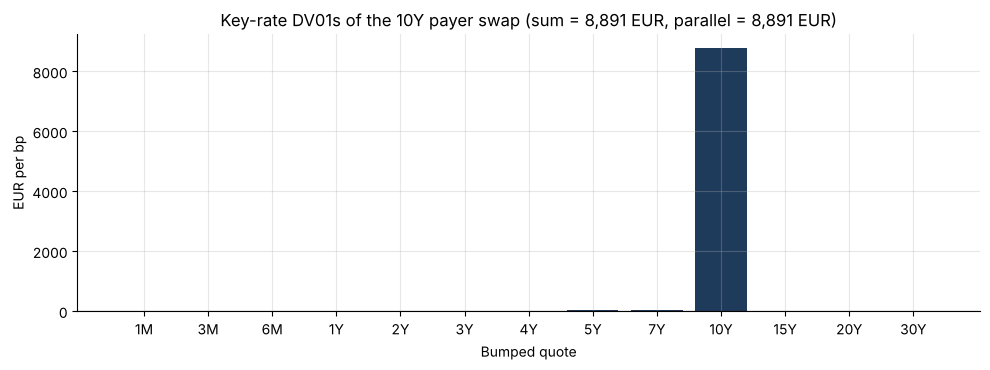

In [4]:
N, K, T = 10_000_000, 0.03, 10
pricer = lambda c: swap_npv(c, N, K, T, pay_fixed=True)
npv = pricer(curve)
par = par_swap_rate(curve, T)
total_dv01 = dv01(quotes, pricer)
print(f"Par 10Y rate: {par:.4%}   NPV of the payer swap: {npv:,.0f} EUR")
print(f"DV01 (+1 bp on all quotes, curve rebuilt): {total_dv01:,.0f} EUR per bp")

kr = pd.Series(key_rate_dv01s(quotes, pricer))
plt.figure(figsize=(10, 3.8))
plt.bar(kr.index, kr.values, color=[NAVY if v >= 0 else BORDEAUX for v in kr.values])
plt.axhline(0, color="black", lw=0.8)
plt.title(f"Key-rate DV01s of the 10Y payer swap (sum = {kr.sum():,.0f} EUR, parallel = {total_dv01:,.0f} EUR)")
plt.ylabel("EUR per bp"); plt.xlabel("Bumped quote")
plt.tight_layout(); plt.savefig("images/key_rates.png", dpi=150); plt.show()

**Reading the chart.** Almost all the risk sits on the 10Y quote: a 10-year swap is
essentially hedged with the 10-year par swap. The small bars on the 1Y to 7Y pillars come
from the off-market fixed rate: the swap is not at par, so its coupons are sensitive to
the discount factors at those dates. Pillars beyond 10Y carry no risk. The key-rate DV01s
add up to the parallel DV01, which the tests check.

## 4. Bond analytics

A 10-year 3% annual-coupon bond, priced off the curve. Duration gives the first-order
price change for a yield move, $\Delta P/P \approx -D_{mod}\,\Delta y$, and convexity adds
the second-order term $+\tfrac12 C\,\Delta y^2$.

In [5]:
price = bond_price_from_curve(curve, 0.03, 10)
y = yield_to_maturity(price, 0.03, 10)
risk = bond_risk(y, 0.03, 10)
print(f"Price {price:.3f}   yield {y:.4%}")
pd.Series(risk).round(4).to_frame("10Y 3% bond").T

Price 102.971   yield 2.6578%


,price,macaulay_duration,modified_duration,convexity,dv01
10Y 3% bond,102.9707,8.8072,8.5792,87.9202,0.0883


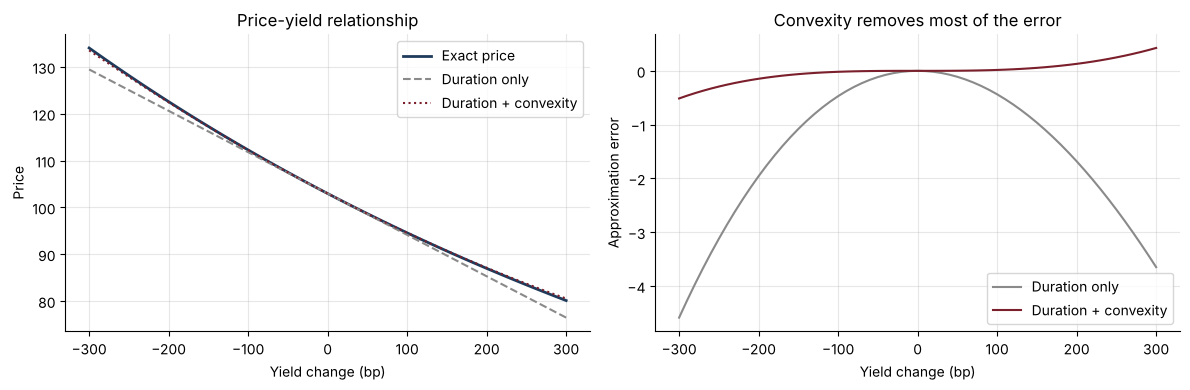

In [6]:
shifts = np.linspace(-0.03, 0.03, 61)
exact = np.array([bond_price_from_yield(y + s, 0.03, 10) for s in shifts])
dur_only = price * (1 - risk["modified_duration"] * shifts)
dur_conv = price * (1 - risk["modified_duration"] * shifts + 0.5 * risk["convexity"] * shifts**2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(shifts * 1e4, exact, color=NAVY, lw=2, label="Exact price")
axes[0].plot(shifts * 1e4, dur_only, color=GREY, ls="--", label="Duration only")
axes[0].plot(shifts * 1e4, dur_conv, color=BORDEAUX, ls=":", label="Duration + convexity")
axes[0].set(xlabel="Yield change (bp)", ylabel="Price", title="Price-yield relationship"); axes[0].legend()
axes[1].plot(shifts * 1e4, dur_only - exact, color=GREY, label="Duration only")
axes[1].plot(shifts * 1e4, dur_conv - exact, color=BORDEAUX, label="Duration + convexity")
axes[1].set(xlabel="Yield change (bp)", ylabel="Approximation error", title="Convexity removes most of the error")
axes[1].legend(); plt.tight_layout(); plt.savefig("images/bond_convexity.png", dpi=150); plt.show()

## Conclusions
- The bootstrapped curve reprices all 13 market instruments to machine precision.
- The 10Y payer swap at 3% is worth about −€300k with a DV01 of about +€8,800 per bp,
  concentrated on the 10Y pillar; bucketed risks add up to the parallel risk.
- For a ±300 bp move, the duration-only approximation is off by several points of price,
  while adding convexity cuts the error by an order of magnitude.
- **Next steps:** multi-curve (€STR discounting, Euribor forwarding), day-count conventions
  and calendars, smoother interpolation (monotone convex).